<a href="https://colab.research.google.com/github/doanxuantuong/PlantLeafDiseaseClassification/blob/tuong/Plant_Leaf_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q timm grad-cam gradio tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, random, time, json, hashlib, shutil, warnings
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_recall_fscore_support, classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True
sns.set_style("whitegrid")

SEED = 42
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CHƯA BẬT GPU. Vào Runtime > Change runtime type > T4 GPU rồi chạy lại.")

CFG = dict(
    IMG_SIZE=224,
    BATCH=64,
    EPOCHS=6,
    FREEZE_EPOCHS=1,      # epoch đầu chỉ train lớp phân loại (warm-up), sau đó fine-tune toàn bộ
    PATIENCE=3,           # early stopping theo F1-macro trên tập Validation
    WD=0.0,
    NUM_WORKERS=2,
    MAX_PER_CLASS=None,   # đặt 100 để chạy thử nhanh; None = dùng toàn bộ dữ liệu
    OUTLIER_RATE=0.01,    # tỉ lệ ảnh bị đánh dấu bất thường trong mỗi lớp
    WORK_DIR="/content/work",
    DRIVE_OUT="/content/drive/MyDrive/datamining_plant_out",
)


# ---- Hàm dùng chung
def pretty(label):
    return label.replace("___", " - ").replace("_", " ")


def show_grid(paths, titles, ncols=4, size=3):
    n = len(paths); nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, p, t in zip(axes, paths, titles):
        ax.imshow(Image.open(p).convert("RGB")); ax.set_title(t, fontsize=8)
    plt.tight_layout(); plt.show()


def make_eval_tf(mean, std, size=None):
    size = size or CFG["IMG_SIZE"]
    return T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize(mean, std)])


class ImgDS(Dataset):
    def __init__(self, paths, labels, tf):
        self.paths = list(paths); self.labels = list(labels); self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), int(self.labels[i])

CHƯA BẬT GPU. Vào Runtime > Change runtime type > T4 GPU rồi chạy lại.


In [3]:
from google.colab import drive
drive.mount("/content/drive")

SRC_DIR = "/content/drive/MyDrive/N4k1/DataMining"   # <-- SỬA: thư mục Drive chứa 2 file dataset
OUT = Path(CFG["DRIVE_OUT"]); OUT.mkdir(parents=True, exist_ok=True)
RAW = Path(CFG["WORK_DIR"]) / "raw"; RAW.mkdir(parents=True, exist_ok=True)

def extract_all(src, dst):
    for f in sorted(Path(src).iterdir()):
        print(f"- {f.name}  ({f.stat().st_size / 1e6:.1f} MB)" if f.is_file() else f"- {f.name}/ (thư mục)")
        if not f.is_file():
            continue
        out = dst / f.stem
        if out.exists():
            print("   đã giải nén trước đó, bỏ qua"); continue
        try:
            shutil.unpack_archive(str(f), str(out)); print("   giải nén ->", out)
        except (shutil.ReadError, ValueError):
            print("   không giải nén được (.rar/.7z cần: !apt-get -qq install unrar p7zip-full)")

extract_all(SRC_DIR, RAW)
for z in list(RAW.rglob("*.zip")):            # file zip lồng trong zip
    out = z.with_suffix("")
    if not out.exists():
        shutil.unpack_archive(str(z), str(out))

Mounted at /content/drive
- Data for Identification of Plant Leaf Diseases Using a 9-layer Deep Convolutional Neural Network.zip  (1791.0 MB)
   giải nén -> /content/work/raw/Data for Identification of Plant Leaf Diseases Using a 9-layer Deep Convolutional Neural Network
- Plant_Leaf_Disease_Classification.ipynb  (0.0 MB)
   không giải nén được (.rar/.7z cần: !apt-get -qq install unrar p7zip-full)
- lab1/ (thư mục)
- lab2/ (thư mục)
- lab3/ (thư mục)
- lab4/ (thư mục)
- lab5/ (thư mục)


In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
EXCLUDE_KW = ["__macosx"]    # nếu bộ dữ liệu có nhiều phiên bản ảnh, thêm "grayscale", "segmented" để chỉ dùng ảnh màu

def scan(root):
    rows = []
    for p in Path(root).rglob("*"):
        if (p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("._")
                and not any(k in str(p).lower() for k in EXCLUDE_KW)):
            rows.append((str(p), p.parent.name))
    return pd.DataFrame(rows, columns=["path", "label"])

df = scan(RAW)
print("Tổng số ảnh:", len(df), "| Số lớp (theo tên thư mục):", df.label.nunique())

# Kiểm tra cấu trúc thư mục để chắc nhãn đúng
top = (df.path.str.replace(str(RAW) + "/", "", regex=False).str.split("/").str[:2].str.join("/"))
print(top.value_counts().head(15))
print("\nVí dụ nhãn:", sorted(df.label.unique())[:6])
if df.label.nunique() != 38:
    print("\nChú ý: đề tài nêu 38 lớp nhưng tìm được", df.label.nunique(),
          "-> kiểm tra lại cấu trúc ở trên (có thể cần chỉnh EXCLUDE_KW hoặc cách lấy nhãn).")

Tổng số ảnh: 116934 | Số lớp (theo tên thư mục): 39
path
Data for Identification of Plant Leaf Diseases Using a 9-layer Deep Convolutional Neural Network/Data for Identification of Plant Leaf Diseases Using a 9-layer Deep Convolutional Neural Network    116934
Name: count, dtype: int64

Ví dụ nhãn: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Background_without_leaves', 'Blueberry___healthy']

Chú ý: đề tài nêu 38 lớp nhưng tìm được 39 -> kiểm tra lại cấu trúc ở trên (có thể cần chỉnh EXCLUDE_KW hoặc cách lấy nhãn).


# EDA


Số ảnh: 116934 | Số lớp: 39
Nhiều nhất: Orange - Haunglongbing (Citrus greening) (11014) | Ít nhất: Potato - healthy (1152) | Tỉ lệ mất cân bằng: 9.6x


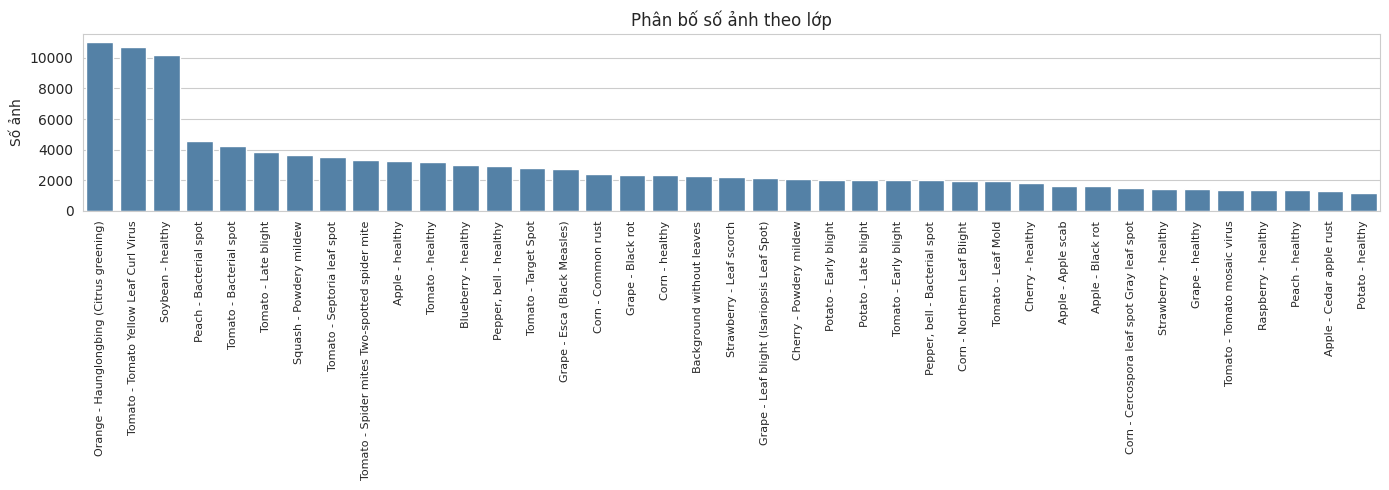


Số lớp theo loài cây:
plant
Tomato                       10
Grape                         4
Apple                         4
Corn                          4
Potato                        3
Cherry                        2
Pepper,_bell                  2
Strawberry                    2
Peach                         2
Background_without_leaves     1
Blueberry                     1
Orange                        1
Raspberry                     1
Squash                        1
Soybean                       1

Ảnh lá khỏe mạnh: 33552 | ảnh lá bệnh: 83382


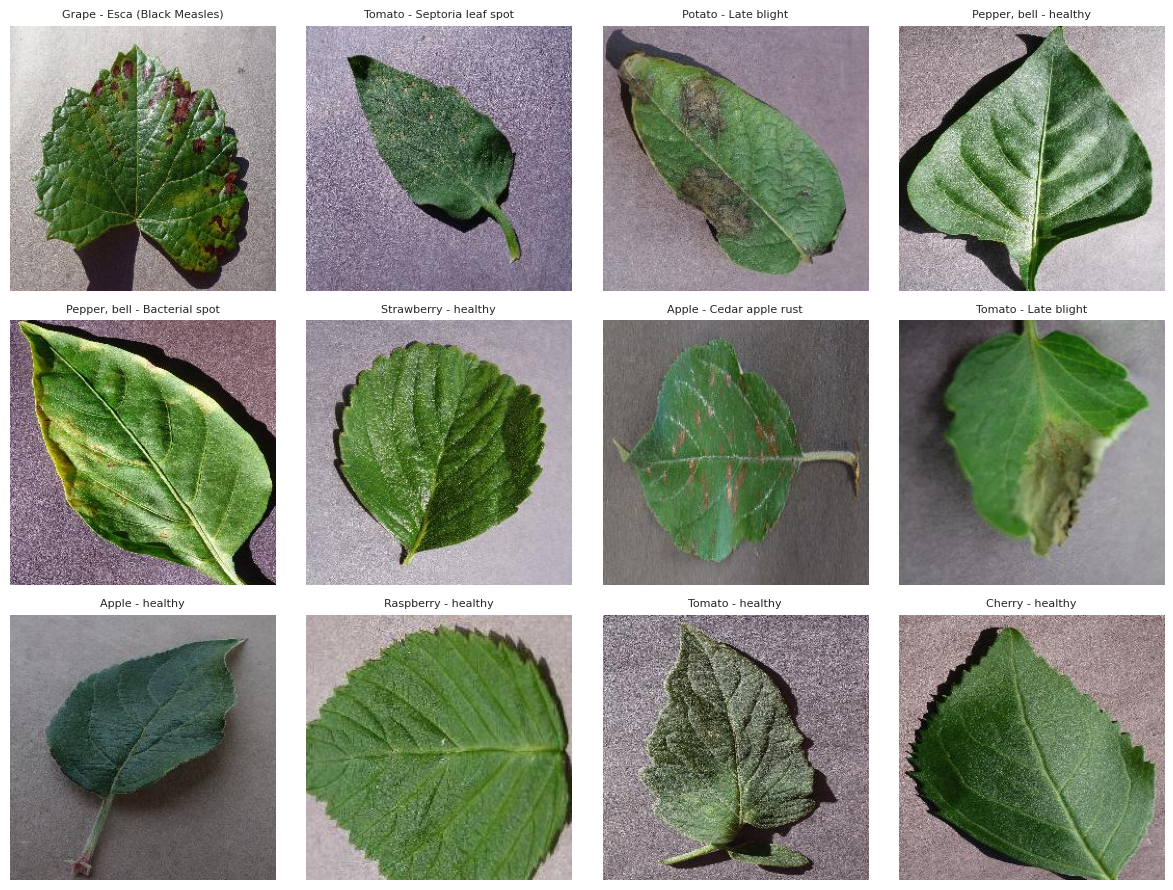

Kích thước ảnh phổ biến (mẫu 300 ảnh): [((256, 256), 280), ((204, 204), 12), ((256, 192), 7), ((350, 350), 1)]


In [5]:
cnt = df.label.value_counts()
print(f"Số ảnh: {len(df)} | Số lớp: {df.label.nunique()}")
print(f"Nhiều nhất: {pretty(cnt.idxmax())} ({cnt.max()}) | Ít nhất: {pretty(cnt.idxmin())} ({cnt.min()}) "
      f"| Tỉ lệ mất cân bằng: {cnt.max() / cnt.min():.1f}x")

plt.figure(figsize=(14, 5))
sns.barplot(x=[pretty(i) for i in cnt.index], y=cnt.values, color="steelblue")
plt.xticks(rotation=90, fontsize=8); plt.ylabel("Số ảnh"); plt.title("Phân bố số ảnh theo lớp")
plt.tight_layout(); plt.show()

df["plant"] = df.label.str.split("___").str[0]
df["healthy"] = df.label.str.lower().str.contains("healthy")
print("\nSố lớp theo loài cây:")
print(df.groupby("plant").label.nunique().sort_values(ascending=False).to_string())
print(f"\nẢnh lá khỏe mạnh: {df.healthy.sum()} | ảnh lá bệnh: {(~df.healthy).sum()}")

rng = np.random.default_rng(SEED)
labs = rng.choice(sorted(df.label.unique()), size=min(12, df.label.nunique()), replace=False)
paths = [df[df.label == l].path.sample(1, random_state=SEED).iloc[0] for l in labs]
show_grid(paths, [pretty(l) for l in labs])

sizes = Counter(Image.open(p).size for p in df.path.sample(min(300, len(df)), random_state=SEED))
print("Kích thước ảnh phổ biến (mẫu 300 ảnh):", sizes.most_common(5))

#